In [1]:
import badgers
badgers.__version__

'0.0.15'

In [2]:
from badgers.generators.tabular_data.drift.causal import CausalDriftGenerator

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import pandas as pd

In [4]:
def generate_linear_data(graph, n_samples=100, rng=None, coefficients=None):
    """Generate data from a linear structural equation model on a DAG.

    Each edge (u -> v) carries a coefficient w. Every node value is
        v = sum_{u in parents(v)} w_{u,v} * u + noise
    with noise ~ N(0, 1).
    """
    if rng is None:
        rng = np.random.default_rng(42)
    if coefficients is None:
        coefficients = {edge: 1.0 for edge in graph.edges()}

    nodes = list(graph.nodes())
    node_to_idx = {node: i for i, node in enumerate(nodes)}
    X = np.zeros((n_samples, len(nodes)))
    for node in nx.topological_sort(graph):
        idx = node_to_idx[node]
        parents = list(graph.predecessors(node))
        if not parents:
            X[:, idx] = rng.normal(size=n_samples)
        else:
            X[:, idx] = rng.normal(size=n_samples)
            for parent in parents:
                coef = coefficients.get((parent, node), 1.0)
                X[:, idx] += coef * X[:, node_to_idx[parent]]
    return X, {node: i for i, node in enumerate(nodes)}


def draw_graph(graph, title=None):
    """Draw a DAG with node labels."""
    fig, ax = plt.subplots(1, figsize=(6, 2))
    pos = nx.spring_layout(graph, seed=42)
    nx.draw(graph, pos, ax=ax, node_color="lightblue", node_size=800, arrowsize=15)
    nx.draw_networkx_labels(graph, pos, ax=ax)
    if title:
        ax.set_title(title, fontsize=12)
    ax.axis("off")
    return fig


def plot_2panel(X, Xt, yt, x_idx=0, y_idx=1, x_name="X", y_name="Y"):
    """Original | Transformed scatter of two dimensions.

    The transformed panel is coloured by the generator's labels (which rows
    received the defect). Rows with NaN values are drawn as black 'x' markers.
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
    sns.scatterplot(x=X[:, x_idx], y=X[:, y_idx], color="C0", ax=axes[0])
    sns.scatterplot(x=Xt[:, x_idx], y=Xt[:, y_idx], color="C1", ax=axes[1])
    axes[0].set_title("Original")
    axes[1].set_title("Transformed")
    axes[0].set_xlabel(x_name)
    axes[1].set_xlabel(x_name)
    axes[0].set_ylabel(y_name)
    axes[1].set_ylabel(y_name)
    plt.tight_layout()
    return fig

## 1. Building the causal graph

Unlike the classic Badgers generators, the causal generators take a **causal graph** (a directed acyclic graph, or DAG) as input. The graph plays two roles:

1. **It defines the data generating process.** We generate the data *from* the graph using a linear structural equation model, so the graph genuinely explains how the columns are related.
2. **It drives the defect.** When a node is perturbed, the effect **propagates to its descendants** along the directed edges and nowhere else.

For these tutorials we use a simple **chain** `X → Y → Z`:

- **X** is a root (exogenous) node.
- **Y** depends on X.
- **Z** depends on Y.

We represent the graph with `networkx.DiGraph` and provide an explicit `column_mapping` that tells the generator which column of the data each node lives in.


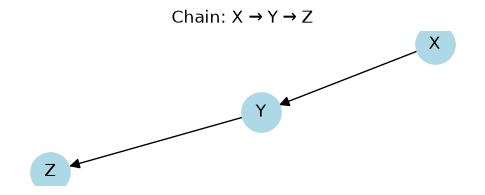

In [5]:
# --- Build the chain X -> Y -> Z ---
chain = nx.DiGraph()
chain.add_edges_from([("X", "Y"), ("Y", "Z")])

draw_graph(chain, title="Chain: X → Y → Z")
plt.show()


## 2. Generating data from the DAG

We draw 100 samples from the chain. Each node is a weighted sum of its parents plus Gaussian noise; the edge weights set the strength of each causal effect.


In [6]:
rng = np.random.default_rng(42)

X, column_mapping = generate_linear_data(
    chain, n_samples=100, rng=rng,
    coefficients={("X", "Y"): 2.0, ("Y", "Z"): 0.5},
)
print(f"X shape: {X.shape}")
print(f"column_mapping: {column_mapping}")


X shape: (100, 3)
column_mapping: {'X': 0, 'Y': 1, 'Z': 2}


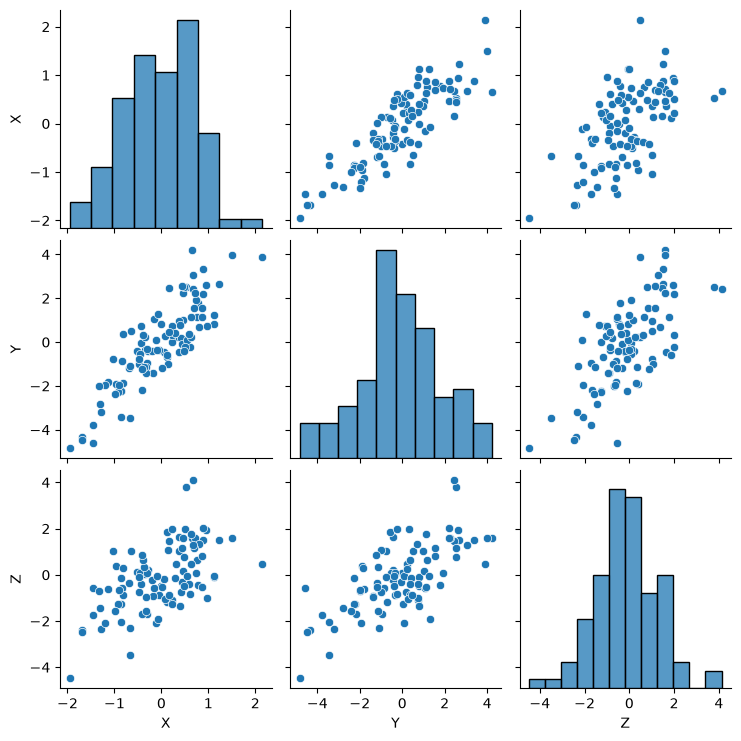

In [7]:
sns.pairplot(pd.DataFrame(X,columns=column_mapping.keys()))

## 3. Fitting the data generation process (DGP)

Causal generators run in **two phases**:

1. **`fit(X, graph, column_mapping)`** — stores the causal structure and, by default, fits a deterministic per-node least-squares data generation process (the `OlsDGP` backend) to the *original* data. It learns, for every node, the linear coefficients from its parents and the residual noise.
2. **`generate(...)`** — perturbs the chosen node(s), then **propagates** the effect to descendants using the fitted structural equations.

Fitting is deterministic (pure NumPy) and needs no extra. Custom estimation backends implementing the `DGP` protocol can be injected via the `dgp=` argument of `fit` (PyMC- and DoWhy-GCM-based backends are planned follow-ups; the optional `causal` extra, `pip install "badgers[causal]"`, installs PyMC + PyTensor for writing such backends).


In [8]:
gen = CausalDriftGenerator(random_generator=np.random.default_rng(0))
gen.fit(X.copy(), chain, column_mapping)
print("DGP fitted on", X.shape[0], "rows")


DGP fitted on 100 rows


## 4. Generate causally-propagated drift

The `CausalDriftGenerator` applies a **systematic shift** (drawn once, then applied to every affected row) to a perturbation node and propagates it to descendants. Unlike noise, the shift is *constant* — the whole node (and its downstream effect) moves together.

`drift_std` is expressed in units of the column's standard deviation.


In [9]:
Xt, yt = gen.generate(
    X.copy(), y=None,
    perturbation_nodes=["Y"],
    drift_std=5.0,
)
print(f"output shape: {Xt.shape}")


output shape: (100, 3)


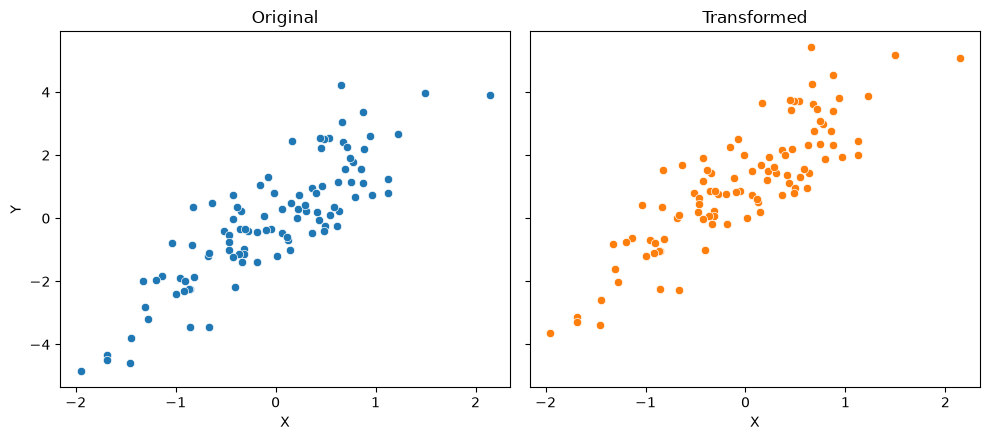

In [10]:
_ = plot_2panel(X, Xt, yt, x_idx=0, y_idx=1, x_name='X', y_name='Y')

### Propagation to the descendant (Y → Z)

Because the drift is a single systematic shift, the whole Y → Z cloud **translates together** — the cloud moves as a unit rather than its points being pushed apart individually. Note that it does *not* collapse onto a line: the propagation adds only the delta `beta_YZ * shift` on top of Z's original values, so Z's own exogenous noise is preserved and the cloud keeps its internal scatter — only its *position* changes. This is what distinguishes drift from noise: drift translates the cloud, noise scatters it."

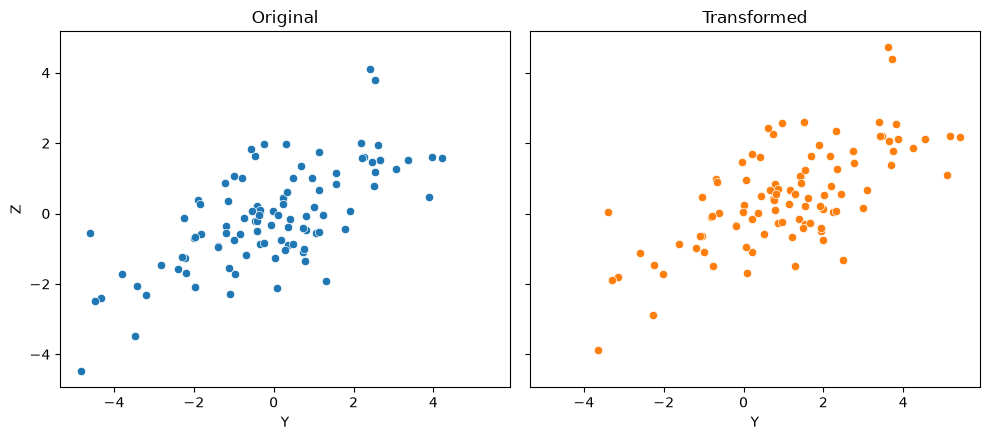

In [11]:
_ = plot_2panel(X, Xt, yt, x_idx=1, y_idx=2, x_name='Y', y_name='Z')

## Summary

1. Drift is a *single* systematic shift, drawn once and applied to all affected rows.
2. It propagates to descendants via the structural equations, and each descendant keeps its own exogenous noise.
3. In a scatter plot it shows up as a rigid translation of the cloud: the cloud's position moves, but its internal scatter is preserved.